# 05 — Réseau de neurones à masquage, puis mélange avec le LightGBM

Le LightGBM (notebook 04) fait 72,7 W sur dev, mais il ne voit que des variables construites à la main, point par point. Un réseau voit **toute la courbe d'un coup** : il peut exploiter des structures non codées (forme du cycle de la veille, cohérence entre points voisins dans le trou). C'est aussi un modèle de nature différente : ses erreurs devraient être moins corrélées à celles du LightGBM, d'où l'intérêt d'un **mélange**.

**Règles** : entraînement sur des courbes du **réservoir** uniquement (les mêmes que le LightGBM, avec le même KNN hors pli) ; arrêt anticipé sur une partie du réservoir ; poids du mélange choisi sur d'**autres** courbes du réservoir ; **dev** pour un petit nombre d'évaluations, **real** pour vérifier, **holdout** intouché.

| Section | Contenu |
|---|---|
| a | Test de vitesse et architectures |
| b | Séquences d'entraînement |
| c | Entraînement et courbes d'apprentissage |
| d | Mélange : poids choisi sur des courbes de calibration |
| e | Évaluation sur dev et real |
| f | Un exemple |
| — | Constat → conséquence |

In [1]:
# torch et LightGBM embarquent chacun leur propre bibliothèque OpenMP : si les deux calculent
# en parallèle sur CPU dans le même processus, l'un plante (erreur de segmentation). Ce
# notebook utilise les deux ; un seul thread OpenMP évite le conflit. À fixer avant les imports.
import os

os.environ["OMP_NUM_THREADS"] = "1"

In [2]:
# Imports et configuration
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator

from enedis_imputation.deep import (
    TCN,
    TrainConfig,
    build_sequence_training_set,
    calibration_set,
    count_parameters,
    device,
    lightgbm_prediction,
    make_blend_method,
    make_network_method,
    make_sequences,
    network_prediction,
    split_by_group,
    train_or_load,
)
from enedis_imputation.gbm import (
    TRAIN_CACHE,
    GBMConfig,
    build_training_set,
    make_method,
    train_cached,
)
from enedis_imputation.holes import LENGTH_LABELS, hole_length_per_point, hole_runs, length_bucket
from enedis_imputation.knn import BEST_DISTANCE, BEST_PREDICTOR, anchored_knn, search
from enedis_imputation.tracking import log_evaluation, setup_mlflow
from enedis_imputation.validation import evaluate, load_split, motif_masks, paired_difference
from enedis_imputation.viz import PALETTE as P
from enedis_imputation.viz import method_color, plot_imputation, save_fig, set_conclusion, set_style

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
dev, real = load_split("dev"), load_split("real")  # le holdout n'est pas chargé
motifs = motif_masks().to_numpy()
setup_mlflow("05_deep_learning")
print("Calcul sur :", device())

# LightGBM de l'étape 5 (relu depuis le cache)
gbm_cfg = GBMConfig("residual", 63)
ts = build_training_set(dev.reservoir, motifs)
_, booster, _ = train_cached(ts, gbm_cfg, TRAIN_CACHE.with_suffix(".json").read_text())
del ts

Calcul sur : mps


## a. Test de vitesse et architectures

Mesures faites avant tout entraînement (lots de 32 courbes de 1 057 pas, 450 lots par epoch, MacBook Air M1) :

| Modèle | Paramètres | Champ réceptif | mps | cpu |
|---|---|---|---|---|
| TCN, dilatations 1→64 répétées 2 fois | 234 k | 509 pas | 125 s/epoch | 1 159 s/epoch |
| **TCN, dilatations 1→64 (une pile)** | **117 k** | **255 pas** | **68 s/epoch** | — |
| **Transformer sur patchs de 8 pas** | **244 k** | toute la courbe | **23 s/epoch** | 36 s/epoch |

Le TCN à deux piles aurait coûté ~42 min à lui seul : on garde **une seule pile** (255 pas, plus de 5 jours, au-delà des 96 pas demandés). Les convolutions dilatées sont lentes sur `mps` (la normalisation n'y est pour rien : sans elle, 104 s/epoch).

**Mesure à chaud.** Le MacBook Air M1 n'a pas de ventilateur et ralentit sous charge prolongée : le débit du TCN a été remesuré sur 3 min 30 de calcul continu, avec une seule synchronisation CPU–GPU par epoch (lire la perte à chaque lot forçait le CPU à attendre le GPU et triplait le temps). Résultat : 69–70 s/epoch, stable, sans ralentissement thermique — confirmé par l'entraînement réel (20 epochs, 69–73 s chacune, 23 min).

**Transformer : abandonné.** Lancé après le TCN, il a été arrêté à l'epoch 12 sur 30 (environ 37 s/epoch) : sa meilleure validation était de 65,2 W, contre 61,1 W pour le TCN, avec une progression qui ralentissait. Son historique partiel est documenté ci-dessous ; seul le TCN est utilisé ensuite.

**Entrées** (8 canaux, normalisés par le niveau moyen observé de la courbe + 1 W) : valeurs observées (0 dans les trous), masque, KNN ancré, interpolation, écart-type des voisines, heure (sin, cos), week-end. **Sortie** : le résidu y − KNN ancré. **Perte** : L1 sur les seuls points masqués, remise en watts.

In [3]:
architectures = {"Réseau TCN": TCN(repeats=1)}
pd.DataFrame(
    {
        name: {
            "paramètres": count_parameters(m),
            "champ réceptif (pas)": getattr(m, "receptive_field", "courbe entière"),
        }
        for name, m in architectures.items()
    }
).T

,paramètres,champ réceptif (pas)
Réseau TCN,117249,255


## b. Séquences d'entraînement

Les **mêmes** 8 000 courbes du réservoir que le LightGBM, chacune trouée par les deux mêmes motifs, avec le **même KNN hors pli** (5 plis) : 16 000 séquences. 10 % des courbes d'origine (et leurs deux copies) servent à l'arrêt anticipé — jamais dev.

In [4]:
seqs = build_sequence_training_set(dev.reservoir, motifs)
train_idx, valid_idx = split_by_group(seqs.groups, 0.1)
train, valid = seqs.subset(train_idx), seqs.subset(valid_idx)
del seqs
print(
    f"Entraînement : {len(train_idx):,} séquences ; validation : {len(valid_idx):,} "
    f"({int(valid.mask.sum()):,} points masqués)".replace(",", " ")
)
print(f"Mémoire des entrées d'entraînement : {train.inputs.nbytes / 1e6:.0f} Mo")
knn_valid = float(np.abs(valid.target).sum() / valid.mask.sum())
print(f"MAE du KNN ancré seul sur la validation : {knn_valid:.2f} W (le réseau doit faire mieux)")

Entraînement : 14 400 séquences ; validation : 1 600 (206 673 points masqués)
Mémoire des entrées d'entraînement : 487 Mo
MAE du KNN ancré seul sur la validation : 74.20 W (le réseau doit faire mieux)


## c. Entraînement et courbes d'apprentissage

In [5]:
configs = {"Réseau TCN": TrainConfig(max_epochs=20)}
files = {"Réseau TCN": "deep_tcn"}
models, histories, run_ids = {}, {}, {}
for name, arch in architectures.items():
    model, hist = train_or_load(arch, train, valid, configs[name], files[name])
    models[name], histories[name] = model, hist
    best = hist.loc[hist["valid_mae"].idxmin()]
    with mlflow.start_run(run_name=name) as run:
        mlflow.log_params(
            configs[name].__dict__
            | {
                "architecture": type(arch).__name__,
                "parametres": count_parameters(arch),
                "champ_receptif": getattr(arch, "receptive_field", -1),
                "train_sequences": len(train.scale),
                "valid_sequences": len(valid.scale),
            }
        )
        for _, h in hist.iterrows():
            mlflow.log_metrics(
                {"train_mae": h["train_mae"], "valid_mae": h["valid_mae"], "lr": h["lr"]},
                step=int(h["epoch"]),
            )
        mlflow.log_metrics(
            {
                "best_valid_mae": best["valid_mae"],
                "best_epoch": best["epoch"],
                "epochs": len(hist),
                "seconds_per_epoch": hist["seconds"].mean(),
                "train_seconds": hist["seconds"].sum(),
            }
        )
        run_ids[name] = run.info.run_id

# Transformer sur patchs de 8 pas (244 k paramètres) : entraînement arrêté à l'epoch 12 / 30,
# historique relevé dans son journal d'entraînement (validation sur les mêmes courbes).
histories["Réseau transformer (arrêté)"] = pd.DataFrame(
    {
        "epoch": range(1, 13),
        "train_mae": [
            82.90,
            79.10,
            76.85,
            74.60,
            72.94,
            71.78,
            71.29,
            70.71,
            70.17,
            69.90,
            69.47,
            69.34,
        ],
        "valid_mae": [
            75.55,
            73.24,
            70.31,
            68.19,
            66.67,
            66.05,
            65.80,
            65.64,
            66.16,
            65.21,
            65.30,
            65.56,
        ],
        "seconds": [36, 34, 34, 36, 36, 43, 43, 38, 38, 34, 35, 37],
    }
)
with mlflow.start_run(run_name="Réseau transformer (arrêté à l'epoch 12)"):
    mlflow.log_params(
        {
            "architecture": "PatchTransformer",
            "parametres": 244328,
            "patch": 8,
            "statut": "arrêté à l'epoch 12 / 30",
        }
    )
    for _, h in histories["Réseau transformer (arrêté)"].iterrows():
        mlflow.log_metrics(
            {"train_mae": h["train_mae"], "valid_mae": h["valid_mae"]}, step=int(h["epoch"])
        )

summary_train = pd.DataFrame(
    {
        name: {
            "epochs": len(h),
            "meilleure epoch": int(h.loc[h["valid_mae"].idxmin(), "epoch"]),
            "MAE validation (W)": h["valid_mae"].min(),
            "s / epoch": h["seconds"].mean(),
            "entraînement (min)": h["seconds"].sum() / 60,
        }
        for name, h in histories.items()
    }
).T
display(summary_train)
print(f"Référence : KNN ancré seul sur la validation = {knn_valid:.2f} W")

,epochs,meilleure epoch,MAE validation (W),s / epoch,entraînement (min)
Réseau TCN,20.00,17.00,61.12,69.77,23.26
Réseau transformer (arrêté),12.00,10.00,65.21,37.00,7.40


Référence : KNN ancré seul sur la validation = 74.20 W


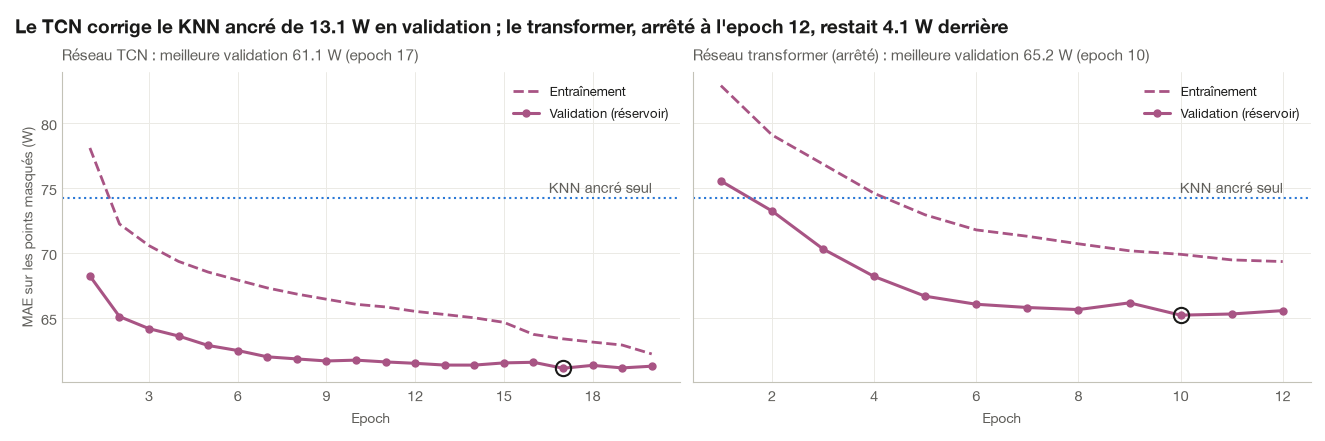

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (name, h) in zip(axes, histories.items(), strict=True):
    ax.plot(
        h["epoch"], h["train_mae"], color=method_color(name), lw=2, ls="--", label="Entraînement"
    )
    ax.plot(
        h["epoch"],
        h["valid_mae"],
        color=method_color(name),
        lw=2.2,
        marker="o",
        ms=5,
        label="Validation (réservoir)",
    )
    ax.axhline(knn_valid, color=method_color("KNN ancré"), ls=":", lw=1.5)
    ax.annotate(
        "KNN ancré seul",
        (h["epoch"].max(), knn_valid),
        xytext=(0, 4),
        textcoords="offset points",
        ha="right",
        color=P["ink_secondary"],
    )
    best = h.loc[h["valid_mae"].idxmin()]
    ax.plot(best["epoch"], best["valid_mae"], "o", ms=11, mfc="none", mec=P["ink"], mew=1.5)
    ax.set_title(
        f"{name} : meilleure validation {best['valid_mae']:.1f} W (epoch {int(best['epoch'])})"
    )
    ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(loc="upper right")
axes[0].set_ylabel("MAE sur les points masqués (W)")
tcn_best = histories["Réseau TCN"]["valid_mae"].min()
tr_best = histories["Réseau transformer (arrêté)"]["valid_mae"].min()
set_conclusion(
    fig,
    f"Le TCN corrige le KNN ancré de {knn_valid - tcn_best:.1f} W en validation ; le "
    f"transformer, arrêté à l'epoch 12, restait {tr_best - tcn_best:.1f} W derrière",
)
save_fig(fig, "n1_courbes_apprentissage");

**Constat → conséquence (entraînement)**

- **Le TCN apprend vite et sans sur-apprentissage visible.**
  - Dès la 1ʳᵉ epoch, il passe sous le KNN ancré seul : 68,2 W contre 74,2 W sur les courbes de validation.
  - Meilleure validation : **61,1 W à l'epoch 17**, soit −13,1 W par rapport au KNN ancré.
  - L'écart entre entraînement et validation reste stable. La validation est plus basse que l'entraînement, ce qui s'explique : les courbes de validation forment un tirage différent, et la perte d'entraînement est une moyenne prise pendant que les poids changent.
- **Coût mesuré sur le MacBook Air M1** : 69–73 s par epoch, du début à la fin, sans ralentissement thermique, soit **23 min pour 20 epochs**.
- **Le transformer sur patchs a été abandonné** à l'epoch 12 : 65,2 W au mieux, 4,1 W derrière le TCN, avec une progression qui ralentissait. Le découpage en patchs de 8 pas brouille probablement les trous de 1–2 points, qui portent la moitié des valeurs à prédire : la sortie d'un jeton est la même tête linéaire pour 8 pas. Le TCN, lui, prédit chaque pas avec un champ réceptif centré.
- → On garde le TCN. La validation progressait encore en fin de course (−0,1 à −0,2 W par epoch) : quelques epochs de plus apporteraient peut-être un peu, au prix du temps machine.

## d. Mélange : poids choisi sur des courbes de calibration

Le LightGBM a été entraîné sur **toutes** les courbes d'entraînement : ses prédictions sur ces courbes ne sont pas hors échantillon. On prend donc **1 000 autres courbes du réservoir**, jamais cibles d'entraînement, trouées par un motif chacune et remplies avec un réservoir qui **les exclut**. Ni le LightGBM ni les réseaux ne les ont vues, et ce n'est pas dev. On y choisit (1) le réseau à mélanger et (2) le poids w de `w · LightGBM + (1 − w) · réseau`.

In [7]:
calib = calibration_set(dev.reservoir, motifs)
nb_cal = search(calib.X_holed, calib.pool, BEST_DISTANCE, k_max=BEST_PREDICTOR.k)
seq_cal = make_sequences(calib.X_holed, calib.pool, nb_cal, calib.y)
cal_mask = seq_cal.mask > 0
y_cal = calib.y.to_numpy().T
cal_cls = length_bucket(hole_length_per_point(calib.X_holed.isna().to_numpy()).T[cal_mask])

cal_pred = {
    "KNN ancré": seq_cal.knn,
    "LightGBM": lightgbm_prediction(booster, gbm_cfg, calib.X_holed, calib.pool, nb_cal),
}
cal_pred |= {name: network_prediction(m, seq_cal) for name, m in models.items()}


def cal_mae(pred: np.ndarray) -> pd.Series:
    """MAE par classe et globale sur la calibration."""
    err = np.abs(pred[cal_mask] - y_cal[cal_mask])
    out = pd.Series(err).groupby(cal_cls, observed=False).mean()
    out["toutes"] = err.mean()
    return out


display(pd.DataFrame({k: cal_mae(v) for k, v in cal_pred.items()}).T.round(1))
net_name = min(models, key=lambda n: cal_mae(cal_pred[n])["toutes"])
print("Réseau retenu pour le mélange (sur la calibration) :", net_name)

weights = np.round(np.arange(0, 1.0001, 0.05), 2)
blend_curve = pd.Series(
    [cal_mae(w * cal_pred["LightGBM"] + (1 - w) * cal_pred[net_name])["toutes"] for w in weights],
    index=weights,
)
w_best = float(blend_curve.idxmin())
err_g = cal_pred["LightGBM"][cal_mask] - y_cal[cal_mask]
err_n = cal_pred[net_name][cal_mask] - y_cal[cal_mask]
print(
    f"w retenu = {w_best:.2f} → {blend_curve.min():.2f} W "
    f"(LightGBM seul {blend_curve[1.0]:.2f} W, réseau seul {blend_curve[0.0]:.2f} W)"
)
print(f"Corrélation des erreurs LightGBM / réseau : {np.corrcoef(err_g, err_n)[0, 1]:.3f}")
with mlflow.start_run(run_name="Mélange LightGBM + réseau") as run:
    run_ids["Mélange"] = run.info.run_id
    mlflow.log_params(
        {"reseau": net_name, "w_lightgbm": w_best, "calibration_curves": len(calib.curves)}
    )
    mlflow.log_metrics(
        {
            "calib_mae_blend": blend_curve.min(),
            "calib_mae_lightgbm": blend_curve[1.0],
            "calib_mae_network": blend_curve[0.0],
        }
    )

,1,2,3-6,7-48,>48,toutes
KNN ancré,57.70,64.40,70.20,99.50,105.40,80.50
LightGBM,53.00,58.40,63.70,86.30,89.90,71.10
Réseau TCN,48.10,54.60,59.70,83.00,87.70,67.30


Réseau retenu pour le mélange (sur la calibration) : Réseau TCN


w retenu = 0.20 → 67.05 W (LightGBM seul 71.10 W, réseau seul 67.32 W)
Corrélation des erreurs LightGBM / réseau : 0.917


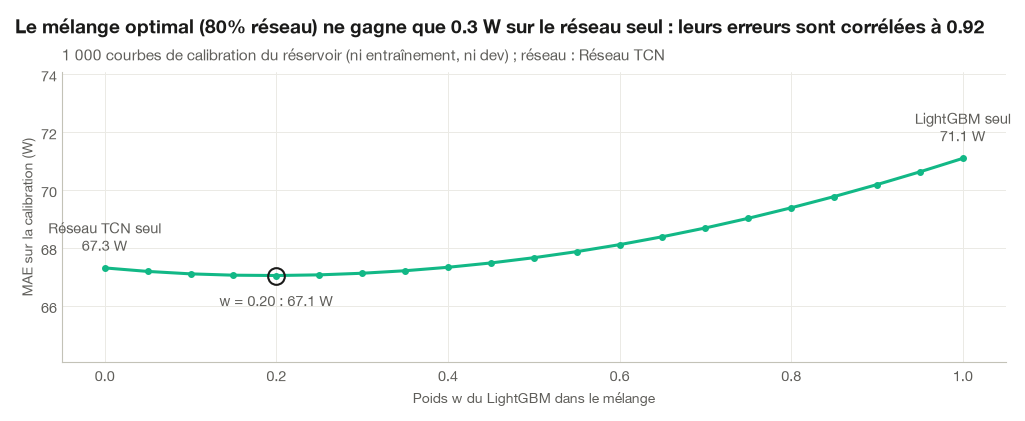

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    blend_curve.index,
    blend_curve.to_numpy(),
    color=method_color("Mélange"),
    lw=2.2,
    marker="o",
    ms=4,
)
ax.plot(w_best, blend_curve.min(), "o", ms=12, mfc="none", mec=P["ink"], mew=1.5)
ax.annotate(
    f"w = {w_best:.2f} : {blend_curve.min():.1f} W",
    (w_best, blend_curve.min()),
    xytext=(0, -22),
    textcoords="offset points",
    ha="center",
    color=P["ink_secondary"],
)
for w, label in [(0.0, net_name), (1.0, "LightGBM")]:
    ax.annotate(
        f"{label} seul\n{blend_curve[w]:.1f} W",
        (w, blend_curve[w]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        va="bottom",
        color=P["ink_secondary"],
    )
ax.set_xlabel("Poids w du LightGBM dans le mélange")
ax.set_ylabel("MAE sur la calibration (W)")
ax.set_ylim(blend_curve.min() - 3, blend_curve.max() + 3)
ax.set_title(
    f"1 000 courbes de calibration du réservoir (ni entraînement, ni dev) ; réseau : {net_name}"
)
gain_mix = min(blend_curve[0.0], blend_curve[1.0]) - blend_curve.min()
corr = np.corrcoef(err_g, err_n)[0, 1]
set_conclusion(
    fig,
    f"Le mélange optimal ({1 - w_best:.0%} réseau) ne gagne que {gain_mix:.1f} W sur le réseau "
    f"seul : leurs erreurs sont corrélées à {corr:.2f}",
)
save_fig(fig, "n2_poids_melange");

**Constat → conséquence (mélange)**

- **Sur les 1 000 courbes de calibration**, jamais vues par aucun modèle, le TCN fait **67,3 W** contre 71,1 W pour le LightGBM. Il est meilleur dans **toutes les classes**, surtout sur les trous courts : 48 W contre 53 W sur 1 point.
- **Le mélange optimal est w = 0,20**, soit 20 % LightGBM et 80 % TCN. Il fait 67,05 W, à peine 0,3 W de mieux que le TCN seul.
- La raison : **les erreurs des deux modèles sont corrélées à 0,92**. Ils partent du même KNN ancré et voient en grande partie la même information. Le mélange ne peut compenser que ce qui diffère.
- → Le poids a été choisi sans dev. On garde le mélange, puisqu'il ne coûte rien de plus à la prédiction que les deux modèles. Mais **le gain vient du réseau**, pas du mélange.

## e. Évaluation sur dev et real

In [9]:
methods = {
    "KNN ancré": anchored_knn,
    "LightGBM": make_method(booster, gbm_cfg),
    net_name: make_network_method(models[net_name]),
    "Mélange": make_blend_method(booster, gbm_cfg, models[net_name], w_best),
}
names = {
    "KNN ancré": "KNN ancré",
    "LightGBM": "LightGBM résidu, 63 feuilles",
    net_name: net_name,
    "Mélange": f"Mélange (w = {w_best:.2f}, {net_name.split()[-1]})",
}
results = {
    split.name: {k: evaluate(m, split, name=names[k]) for k, m in methods.items()}
    for split in (dev, real)
}
for k in (net_name, "Mélange"):
    run_id = run_ids.get(k)
    if run_id:
        with mlflow.start_run(run_id=run_id):
            for s in ("dev", "real"):
                log_evaluation(results[s][k])


def class_table(res: dict) -> pd.DataFrame:
    """MAE par classe (+ globale) de chaque méthode."""
    return pd.DataFrame(
        {k: [*r.by_class["mae"].to_numpy(), r.mae] for k, r in res.items()},
        index=[*LENGTH_LABELS, "toutes"],
    ).T


display(pd.concat({s: class_table(r) for s, r in results.items()}).round(1))
paired = pd.concat(
    {
        (s, f"{k} − LightGBM"): paired_difference(results[s][k], results[s]["LightGBM"])[
            "différence"
        ]
        for s in results
        for k in (net_name, "Mélange")
    },
    axis=1,
).T
display(paired.round(2))
for s in results:
    d = paired_difference(results[s]["Mélange"], results[s][net_name]).loc["toutes"]
    print(
        f"{s} : Mélange − {net_name} = {d['différence']:+.2f} W "
        f"[{d['IC bas']:+.2f}, {d['IC haut']:+.2f}]"
    )
for s in results:
    for k in (net_name, "Mélange"):
        d = paired_difference(results[s][k], results[s]["LightGBM"]).loc["toutes"]
        ci = f"[{d['IC bas']:+.2f}, {d['IC haut']:+.2f}]"
        print(f"{s} : {k} − LightGBM = {d['différence']:+.2f} W {ci}")

1     2   3-6  7-48    >48  toutes
dev  KNN ancré  60.90 70.10 75.30 99.10 108.90   82.10
     LightGBM   55.80 63.00 68.00 85.70  95.70   72.70
     Réseau TCN 50.90 58.60 64.00 82.50  91.20   68.60
     Mélange    50.90 58.40 63.80 82.20  90.80   68.40
real KNN ancré  60.60 69.30 76.40 98.70  93.70   80.40
     LightGBM   55.70 62.50 69.70 85.30  83.20   71.30
     Réseau TCN 50.50 57.70 66.30 81.80  79.60   67.00
     Mélange    50.50 57.60 65.80 81.50  79.20   66.80

classe                         1     2   3-6  7-48   >48  toutes
dev  Réseau TCN − LightGBM -4.96 -4.49 -4.07 -3.12 -4.47   -4.10
     Mélange − LightGBM    -4.95 -4.68 -4.22 -3.51 -4.84   -4.31
real Réseau TCN − LightGBM -5.18 -4.83 -3.43 -3.45 -3.54   -4.24
     Mélange − LightGBM    -5.17 -4.97 -3.88 -3.78 -3.95   -4.45

dev : Mélange − Réseau TCN = -0.21 W [-0.28, -0.15]
real : Mélange − Réseau TCN = -0.20 W [-0.30, -0.10]


dev : Réseau TCN − LightGBM = -4.10 W [-4.54, -3.65]
dev : Mélange − LightGBM = -4.31 W [-4.71, -3.90]


real : Réseau TCN − LightGBM = -4.24 W [-4.86, -3.65]
real : Mélange − LightGBM = -4.45 W [-5.03, -3.90]


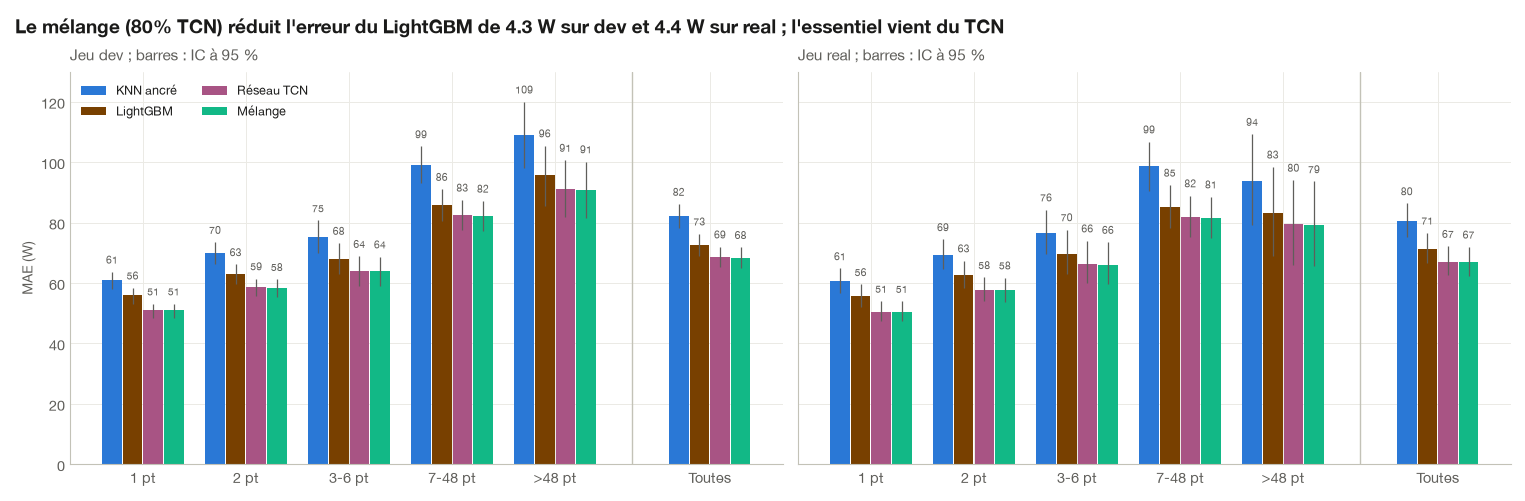

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
groups = [*LENGTH_LABELS, "toutes"]
x = np.arange(len(groups)) + np.array([0, 0, 0, 0, 0, 0.5])
for ax, (s, res) in zip(axes, results.items(), strict=True):
    for i, (name, r) in enumerate(res.items()):
        t = pd.concat(
            [
                r.by_class,
                pd.DataFrame(
                    {"mae": [r.mae], "low": [r.ci[0]], "high": [r.ci[1]]}, index=["toutes"]
                ),
            ]
        ).loc[groups]
        xs = x + (i - 1.5) * 0.2
        ax.bar(xs, t["mae"], width=0.19, color=method_color(name), label=name)
        ax.errorbar(
            xs,
            t["mae"],
            yerr=[t["mae"] - t["low"], t["high"] - t["mae"]],
            fmt="none",
            ecolor=P["ink_secondary"],
            elinewidth=0.9,
        )
        for xi, v, hi in zip(xs, t["mae"], t["high"], strict=True):
            ax.text(
                xi,
                hi + 2,
                f"{v:.0f}",
                ha="center",
                va="bottom",
                fontsize=7.5,
                color=P["ink_secondary"],
            )
    ax.axvline(x[-1] - 0.75, color=P["axis"], lw=1)
    ax.set_xticks(x, [f"{c} pt" for c in LENGTH_LABELS] + ["Toutes"])
    ax.set_title(f"Jeu {s} ; barres : IC à 95 %")
    ax.set_ylim(0, 130)
axes[0].set_ylabel("MAE (W)")
axes[0].legend(loc="upper left", fontsize=9, ncol=2)
d_dev = paired_difference(results["dev"]["Mélange"], results["dev"]["LightGBM"]).loc["toutes"]
d_real = paired_difference(results["real"]["Mélange"], results["real"]["LightGBM"]).loc["toutes"]
set_conclusion(
    fig,
    f"Le mélange ({1 - w_best:.0%} TCN) réduit l'erreur du LightGBM de "
    f"{-d_dev['différence']:.1f} W sur dev et {-d_real['différence']:.1f} W sur real ; "
    "l'essentiel vient du TCN",
)
save_fig(fig, "n3_mae_par_classe");

**Constat → conséquence (dev et real)**

- **Le TCN bat le LightGBM** : −4,1 W sur dev [−4,5 ; −3,7] et −4,2 W sur real [−4,9 ; −3,7]. Le gain existe dans **toutes les classes**, et il est le plus fort sur les trous courts (−5 W sur 1 point).
- **Le mélange (w = 0,20)** : **68,4 W sur dev** et **66,8 W sur real**, soit −4,3 et −4,5 W par rapport au LightGBM.
- **Mélange contre TCN seul** : −0,2 W sur dev comme sur real. C'est un gain petit mais régulier, sur les deux jeux.
- **Dev et real racontent la même histoire**, avec des écarts au LightGBM quasi identiques : ni le choix du réseau, ni le poids du mélange, tous deux faits hors dev, ne sur-ajustent.
- **Depuis le benchmark**, l'erreur sur real est passée de 102,0 à 66,8 W : **−35 %**.

## f. Un exemple : un long trou rempli par le LightGBM, le réseau et le mélange

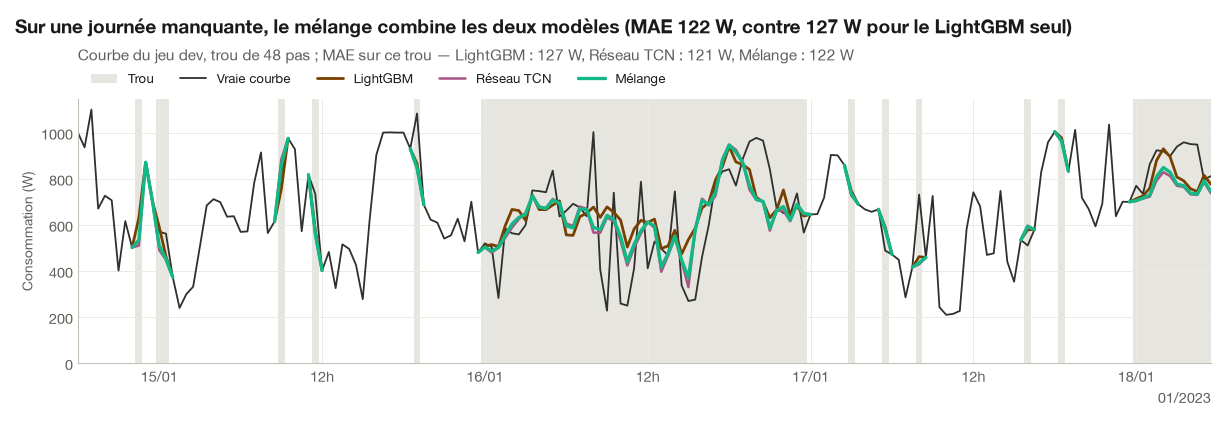

In [11]:
preds = {k: methods[k](dev.X_holed, dev.reservoir) for k in ("LightGBM", net_name, "Mélange")}
runs = hole_runs(dev.mask)
long = runs[runs["length"] == 48].copy()
y_arr = dev.y.to_numpy()
for name, pr in preds.items():
    arr = pr.to_numpy()
    long[name] = [
        np.abs(arr[s : s + n, c] - y_arr[s : s + n, c]).mean()
        for c, s, n in zip(long["curve"], long["start"], long["length"], strict=True)
    ]
# Exemple représentatif : trou intérieur, niveau entre la médiane et le 90e centile, gain du
# mélange sur le LightGBM proche du gain médian positif
long["gain"] = long["LightGBM"] - long["Mélange"]
level = dev.y.mean().to_numpy()[long["curve"]]
inside = (long["start"] >= 48) & (long["start"] + long["length"] <= len(dev.y) - 48)
lo_lvl, hi_lvl = np.percentile(level, [50, 90])
pool = long[inside & (level > lo_lvl) & (level < hi_lvl) & (long["gain"] > 0)]
ex = pool.loc[(pool["gain"] - pool["gain"].median()).abs().idxmin()]
c, s, n = int(ex["curve"]), int(ex["start"]), int(ex["length"])
col = dev.X_holed.columns[c]
fig = plot_imputation(
    dev.y[col],
    {k: v[col] for k, v in preds.items()},
    dev.mask[:, c],
    f"Sur une journée manquante, le mélange combine les deux modèles (MAE "
    f"{ex['Mélange']:.0f} W, contre {ex['LightGBM']:.0f} W pour le LightGBM seul)",
    window=slice(max(0, s - 60), min(len(dev.y), s + n + 60)),
)
fig.axes[0].set_title(
    "Courbe du jeu dev, trou de 48 pas ; MAE sur ce trou — "
    + ", ".join(f"{k} : {ex[k]:.0f} W" for k in preds),
    pad=28,
)
save_fig(fig, "n4_exemple_long_trou");

## Constat → conséquence pour la modélisation

**Constat**

| MAE (W) | 1 pt | 2 pts | 3–6 pts | 7–48 pts | > 48 pts | Toutes |
|---|---|---|---|---|---|---|
| dev — KNN ancré | 60,9 | 70,1 | 75,3 | 99,1 | 108,9 | 82,1 |
| dev — LightGBM | 55,8 | 63,0 | 68,0 | 85,7 | 95,7 | 72,7 |
| dev — TCN | 50,9 | 58,6 | 64,0 | 82,5 | 91,2 | 68,6 |
| dev — **Mélange** | **50,9** | **58,4** | **63,8** | **82,2** | **90,8** | **68,4** |
| real — KNN ancré | 60,6 | 69,3 | 76,4 | 98,7 | 93,7 | 80,4 |
| real — LightGBM | 55,7 | 62,5 | 69,7 | 85,3 | 83,2 | 71,3 |
| real — TCN | 50,5 | 57,7 | 66,3 | 81,8 | 79,6 | 67,0 |
| real — **Mélange** | **50,5** | **57,6** | **65,8** | **81,5** | **79,2** | **66,8** |

- **Le réseau à masquage bat le LightGBM**, de ~4 W sur dev comme sur real. C'est un résultat positif, mais il faut le lire avec ses limites :
  - c'est surtout un meilleur **correcteur du KNN ancré**, puisqu'il part de la même entrée et prédit le même résidu ;
  - il gagne le plus sur les **trous courts**, là où voir la forme locale de la courbe, des deux côtés du trou, compte davantage que des variables construites à la main ;
  - sur les trous longs, son avance se réduit à ~3 W.
- **Le mélange n'apporte que 0,2 W** : les deux modèles se trompent aux mêmes endroits (erreurs corrélées à 0,92).
- **Coût sur un MacBook Air M1** :
  - préparation des séquences : 40 s ;
  - entraînement du TCN : 23 min ;
  - prédiction de 2 000 courbes : ~10 s pour le TCN, ~50 s pour le mélange (le LightGBM tourne sur un seul thread dans ce notebook, voir ci-dessous).
- **Point technique** : torch et LightGBM embarquent chacun leur propre bibliothèque OpenMP. Dans un même processus, leurs calculs parallèles sur CPU entrent en conflit et l'un plante. Ce notebook, comme les tests, fixe `OMP_NUM_THREADS=1` avant tout import.

**→ Conséquence**
- **Le mélange (w = 0,20) devient la méthode de référence**, à 68,4 W sur dev. Le TCN seul en est une version plus simple, à 0,2 W près.
- Pistes, par ordre de rapport gain/coût :
  - un TCN un peu plus profond ou entraîné plus longtemps (la validation progressait encore) ;
  - un TCN qui reçoit directement les voisines mises à l'échelle (10 canaux) plutôt que leur seul agrégat ;
  - des entrées sur la mémoire de la courbe (t ± 48), que le LightGBM exploitait beaucoup et que le TCN doit apprendre seul.
- **Le holdout reste intouché** : il servira une seule fois, pour le score final.